Looking at the top 10 major transit agencies by ridership in the United States when Vehicle Revenue Miles (VRM) is adjusted how does passenger ridership (UPT) respond, and how does this differ between Heavy Rail (subways) and Light Rail Vehicles (LRV's)?

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
#Load the csv file and check information

In [6]:
df=pd.read_csv('Downloads/Complete_Monthly_Ridership_(with_Adjustments_and_Estimates)_20261025.csv')

C:\Users\user\AppData\Local\Temp\ipykernel_1544\2253705021.py:1: DtypeWarning: Columns (0: Legacy NTD ID, 1: VOMS) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('Downloads/Complete_Monthly_Ridership_(with_Adjustments_and_Estimates)_20261025.csv')


In [7]:
df.head()

,NTD ID,Legacy NTD ID,Agency,Mode/Type of Service Status,Reporter Type,UACE CD,UZA Name,Mode,TOS,3 Mode,Date,UPT,VOMS,VRH,VRM,Agency Mode TOS Date,State,FTA Region
0,1,0001,King County,Active,Full Reporter,80389.0,"Seattle--Tacoma, WA",DR,PT,Bus,January 2002,"135,144",574,"53,306","746,158",00001_DR_PT_Active_Full Reporter_80389_2002-01-01,WA,10
1,1,0001,King County,Active,Full Reporter,80389.0,"Seattle--Tacoma, WA",DR,PT,Bus,February 2002,"127,378",574,"46,865","656,324",00001_DR_PT_Active_Full Reporter_80389_2002-02-01,WA,10
2,1,0001,King County,Active,Full Reporter,80389.0,"Seattle--Tacoma, WA",DR,PT,Bus,March 2002,"136,030",574,"51,889","726,578",00001_DR_PT_Active_Full Reporter_80389_2002-03-01,WA,10
3,1,0001,King County,Active,Full Reporter,80389.0,"Seattle--Tacoma, WA",DR,PT,Bus,April 2002,"142,204",574,"52,674","736,975",00001_DR_PT_Active_Full Reporter_80389_2002-04-01,WA,10
4,1,0001,King County,Active,Full Reporter,80389.0,"Seattle--Tacoma, WA",DR,PT,Bus,May 2002,"144,697",574,"53,306","746,158",00001_DR_PT_Active_Full Reporter_80389_2002-05-01,WA,10


In [8]:
df.shape

(372801, 18)

In [9]:
df.describe()

,NTD ID,UACE CD,FTA Region
count,372801.000000,372741.000000,372801.000000
mean,47879.018020,50031.179546,5.497102
std,27389.850199,28637.056371,2.698013
min,1.000000,17.000000,1.000000
25%,30027.000000,22960.000000,4.000000
50%,50008.000000,51755.000000,5.000000
75%,70003.000000,75718.000000,9.000000
max,99479.000000,99999.000000,10.000000


In [10]:
# Verification of data before transformation

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 372801 entries, 0 to 372800
Data columns (total 18 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   NTD ID                       372801 non-null  int64  
 1   Legacy NTD ID                366204 non-null  object 
 2   Agency                       372801 non-null  str    
 3   Mode/Type of Service Status  372801 non-null  str    
 4   Reporter Type                372801 non-null  str    
 5   UACE CD                      372741 non-null  float64
 6   UZA Name                     372741 non-null  str    
 7   Mode                         372801 non-null  str    
 8   TOS                          372801 non-null  str    
 9   3 Mode                       372801 non-null  str    
 10  Date                         372801 non-null  str    
 11  UPT                          372801 non-null  str    
 12  VOMS                         371086 non-null  object 
 13  VRH       

In [12]:
# Data cleanup to cocentrate on the top 10 agencies based on ridership

In [13]:
# Conversion of Ridership (UPT) and Vehicle Revenue Miles (VRM) to integrals because the data in the csv had them stored as a str for easy display, but need them to be a value in order to do calculations with.  Same reason for the date, as it is stored as a str for dispay but will not be easy to use for caluations in charting. To keep data integrity, orignal values can be referenced to since integral forms of the VRM and UPT now have their own columns that I can perform calculations on.

In [14]:
df['UPT_num'] = pd.to_numeric(df['UPT'].astype(str).str.replace(',', ''))
df['VRM_num'] = pd.to_numeric(df['VRM'].astype(str).str.replace(',', ''))

In [15]:
df['Date'] = pd.to_datetime(df['Date'])

C:\Users\user\AppData\Local\Temp\ipykernel_1544\2394721818.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'])


In [16]:
# Verification of data after transformation

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 372801 entries, 0 to 372800
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   NTD ID                       372801 non-null  int64         
 1   Legacy NTD ID                366204 non-null  object        
 2   Agency                       372801 non-null  str           
 3   Mode/Type of Service Status  372801 non-null  str           
 4   Reporter Type                372801 non-null  str           
 5   UACE CD                      372741 non-null  float64       
 6   UZA Name                     372741 non-null  str           
 7   Mode                         372801 non-null  str           
 8   TOS                          372801 non-null  str           
 9   3 Mode                       372801 non-null  str           
 10  Date                         372801 non-null  datetime64[us]
 11  UPT                          372801 n

In [18]:
#Filter main dataset for top 10 ridership agencies based on ridership and Heavy Rail (HR) / Light Rail (LR) only, removing buses, ferries as the concentration is on rail transit

In [19]:
top_10_agencies = df.groupby('Agency')['UPT_num'].sum().sort_values(ascending=False).head(10).index.tolist()
print("Top 10 Agencies Automatically Extracted:")
for i, ag in enumerate(top_10_agencies, 1):
    print(f"Rank {i}: {ag}")

Top 10 Agencies Automatically Extracted:
Rank 1: MTA New York City Transit
Rank 2: Chicago Transit Authority
Rank 3: Los Angeles County Metropolitan Transportation Authority 
Rank 4: Washington Metropolitan Area Transit Authority
Rank 5: Massachusetts Bay Transportation Authority
Rank 6: Southeastern Pennsylvania Transportation Authority
Rank 7: New Jersey Transit Corporation
Rank 8: City and County of San Francisco
Rank 9: County of Miami-Dade 
Rank 10: Metropolitan Atlanta Rapid Transit Authority


In [20]:
rail_df = df[
    (df['Agency'].isin(top_10_agencies)) & 
    (df['Mode'].isin(['HR', 'LR']))
].copy()

In [21]:
rail_df = rail_df.dropna(subset=['UPT_num', 'VRM_num'])

In [22]:
# When you combine all the active months across those specific Heavy Rail and Light Rail modes for your top 10 agencies—and throw out any months with missing reporting—you are left with 3,968 complete, analysis-ready monthly data points.

In [23]:
# Verification of removed null values

In [24]:
rail_df.info()

<class 'pandas.DataFrame'>
Index: 3968 entries, 28999 to 352089
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   NTD ID                       3968 non-null   int64         
 1   Legacy NTD ID                3968 non-null   object        
 2   Agency                       3968 non-null   str           
 3   Mode/Type of Service Status  3968 non-null   str           
 4   Reporter Type                3968 non-null   str           
 5   UACE CD                      3968 non-null   float64       
 6   UZA Name                     3968 non-null   str           
 7   Mode                         3968 non-null   str           
 8   TOS                          3968 non-null   str           
 9   3 Mode                       3968 non-null   str           
 10  Date                         3968 non-null   datetime64[us]
 11  UPT                          3968 non-null   str     

In [25]:
rail_df.head()

,NTD ID,Legacy NTD ID,Agency,Mode/Type of Service Status,Reporter Type,UACE CD,UZA Name,Mode,TOS,3 Mode,Date,UPT,VOMS,VRH,VRM,Agency Mode TOS Date,State,FTA Region,UPT_num,VRM_num
28999,10003,1003,Massachusetts Bay Transportation Authority,Active,Full Reporter,9271.0,"Boston, MA--NH",HR,DO,Rail,2002-01-01,"9,952,800",320,"75,194","1,654,277",10003_HR_DO_Active_Full Reporter_09271_2002-01-01,MA,1,9952800,1654277.0
29000,10003,1003,Massachusetts Bay Transportation Authority,Active,Full Reporter,9271.0,"Boston, MA--NH",HR,DO,Rail,2002-02-01,"9,753,800",320,"68,228","1,501,014",10003_HR_DO_Active_Full Reporter_09271_2002-02-01,MA,1,9753800,1501014.0
29001,10003,1003,Massachusetts Bay Transportation Authority,Active,Full Reporter,9271.0,"Boston, MA--NH",HR,DO,Rail,2002-03-01,"10,469,800",320,"75,194","1,654,277",10003_HR_DO_Active_Full Reporter_09271_2002-03-01,MA,1,10469800,1654277.0
29002,10003,1003,Massachusetts Bay Transportation Authority,Active,Full Reporter,9271.0,"Boston, MA--NH",HR,DO,Rail,2002-04-01,"10,736,100",320,"74,761","1,644,740",10003_HR_DO_Active_Full Reporter_09271_2002-04-01,MA,1,10736100,1644740.0
29003,10003,1003,Massachusetts Bay Transportation Authority,Active,Full Reporter,9271.0,"Boston, MA--NH",HR,DO,Rail,2002-05-01,"10,526,600",320,"76,110","1,674,419",10003_HR_DO_Active_Full Reporter_09271_2002-05-01,MA,1,10526600,1674419.0


In [26]:
rail_df.shape

(3968, 20)

In [27]:
print(rail_df.groupby(['Agency', 'Mode']).size())

Agency                                                     Mode
Chicago Transit Authority                                  HR      296
City and County of San Francisco                           LR      296
County of Miami-Dade                                       HR      296
Los Angeles County Metropolitan Transportation Authority   HR      296
                                                           LR      296
MTA New York City Transit                                  HR      296
Massachusetts Bay Transportation Authority                 HR      296
                                                           LR      296
Metropolitan Atlanta Rapid Transit Authority               HR      296
New Jersey Transit Corporation                             LR      592
Southeastern Pennsylvania Transportation Authority         HR      296
                                                           LR      120
Washington Metropolitan Area Transit Authority             HR      296
dtype: int64


Possible issues in Time-Series Length Across Agencies

When examining the record counts per agency and mode (e.g., New Jersey Transit showing ~592 monthly records for Light Rail versus ~296 for other agencies), two key structural factors explain these variances:

1. Multiple Reporting Sub-Segments
   Major regional authorities like New Jersey Transit operate multiple distinct light rail divisions or separate operating segments that report to the    National Transit Database (NTD) as individual entries. When filtered, these overlapping sub-networks run concurrently, doubling the expected
   monthly row count.

2. Data Coverage
   Some agencies initiated federal reporting later or experienced reporting changes leading to shorter continuous blocks of monthly data (e.g., SEPTA     Light Rail showing 120
   months).

Impact

These differences do not invalidate the analysis, but they highlight the standardizing multi-modal state should adhere to.

In [28]:
#Exploratory Data Analysis (EDA) & Summary Statistics

In [29]:
summary_stats = rail_df.groupby(['Agency', 'Mode']).agg(
    Record_Count=('UPT_num', 'count'),
    Mean_UPT=('UPT_num', 'mean'),
    Median_UPT=('UPT_num', 'median'),
    Std_UPT=('UPT_num', 'std'),
    Min_UPT=('UPT_num', 'min'),
    Max_UPT=('UPT_num', 'max'),
    Total_UPT=('UPT_num', 'sum'),
    Total_VRM=('VRM_num', 'sum')
).reset_index()

In [30]:
summary_stats['Trips_per_VRM'] = summary_stats['Total_UPT'] / summary_stats['Total_VRM']

In [31]:
# Order the output by the total ridership (UPT) with the highest agency, NYC MTA at the top

In [32]:
summary_stats.sort_values(by='Total_UPT', ascending=False)

,Agency,Mode,Record_Count,Mean_UPT,Median_UPT,Std_UPT,Min_UPT,Max_UPT,Total_UPT,Total_VRM,Trips_per_VRM
5,MTA New York City Transit,HR,296,1.912245e+08,197531202.0,3.868086e+07,20254269,253609943,56602441362,8.473828e+09,6.679678
12,Washington Metropolitan Area Transit Authority,HR,296,1.882599e+07,20458319.0,6.174360e+06,1182655,27860355,5572493503,1.802953e+09,3.090760
0,Chicago Transit Authority,HR,296,1.531147e+07,16298314.5,4.477810e+06,2235078,22663990,4532195679,1.695204e+09,2.673540
6,Massachusetts Bay Transportation Authority,HR,296,1.125566e+07,12136002.0,3.183021e+06,1182140,16679922,3331676310,5.379211e+08,6.193615
10,Southeastern Pennsylvania Transportation Autho...,HR,296,6.893006e+06,7301716.0,1.775097e+06,1263591,9821204,2040329682,4.007416e+08,5.091385
8,Metropolitan Atlanta Rapid Transit Authority,HR,296,5.078523e+06,5689745.5,1.722154e+06,993578,7982627,1503242849,5.162102e+08,2.912075
7,Massachusetts Bay Transportation Authority,LR,296,4.971451e+06,5333057.5,1.571460e+06,259090,7543900,1471549430,1.443906e+08,10.191446
4,Los Angeles County Metropolitan Transportation...,LR,296,3.942146e+06,3863438.0,1.099138e+06,725405,5958605,1166875287,3.186260e+08,3.662210
1,City and County of San Francisco,LR,296,3.416400e+06,3791224.0,1.120721e+06,0,5419319,1011254370,1.256476e+08,8.048335
3,Los Angeles County Metropolitan Transportation...,HR,296,3.149356e+06,3509658.5,8.942861e+05,616954,4629231,932209447,1.530996e+08,6.088907


In [33]:
#charts and viualization

Chart 1: Historical Monthly Ridership Trends (Heavy Rail vs. Light Rail)
Goal: Evaluate long-term ridership trends from 2002 to present across the top 10 U.S. transit agencies.

Key Takeaways & Insights:

Dominance of Subways: Heavy Rail (subways) consistently generates higher passenger volume than Light Rail across all years.

COVID-19 Shock: Both trends for light rail and heavy rail show a massive drop in early 2020 due to pandemic stay-at-home orders, followed by a gradual post-covid recovery curve.

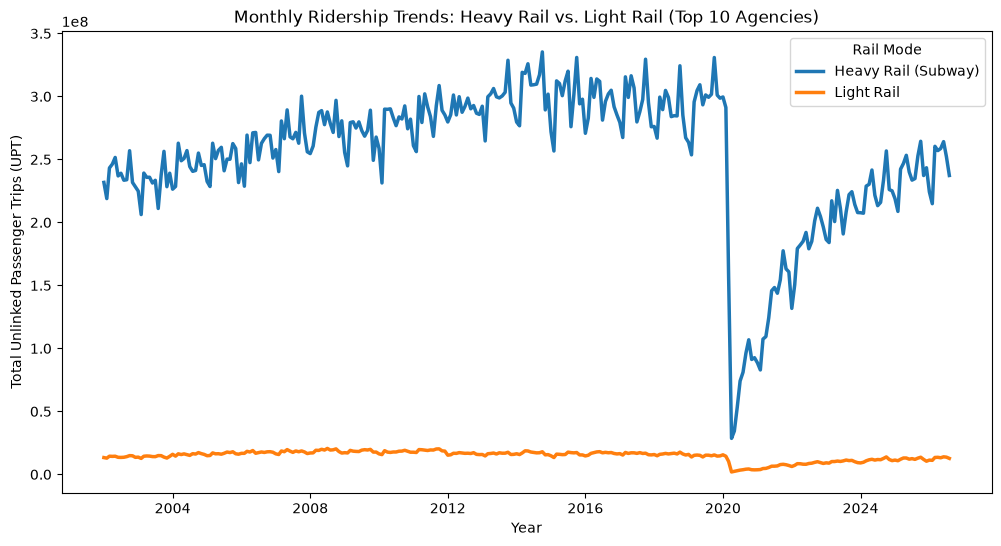

In [34]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=rail_df, 
    x='Date', 
    y='UPT_num', 
    hue='Mode', 
    estimator='sum',  
    errorbar=None,          
    linewidth=2.5
)
plt.title('Monthly Ridership Trends: Heavy Rail vs. Light Rail (Top 10 Agencies)')
plt.xlabel('Year')
plt.ylabel('Total Unlinked Passenger Trips (UPT)')
plt.legend(title='Rail Mode', labels=['Heavy Rail (Subway)', 'Light Rail'])
plt.show()

Chart 2: Vehicle Revenue Miles (VRM) vs. Ridership (UPT)
Goal: Test the direct relationship between Vehicle Revenue Miles and Ridership.

Key Takeaways & Insights:

Strong Positive Linear Relationship: More service mileage correlates with more passenger trips, as seen in the linear cluster trending upward.

Modal Divergence: Heavy Rail data points cluster in the upper-right quadrant (high miles, extremely high ridership), while Light Rail remains concentrated in the lower-left quadrant (lower capacity/demand).

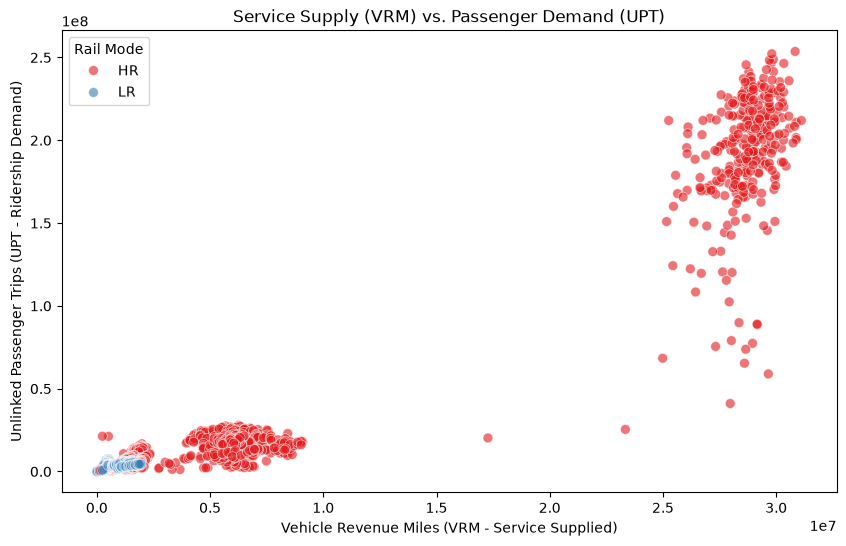

In [35]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rail_df, 
    x='VRM_num', 
    y='UPT_num', 
    hue='Mode', 
    alpha=0.6, 
    palette='Set1',
    s=50
)
plt.title('Service Supply (VRM) vs. Passenger Demand (UPT)')
plt.xlabel('Vehicle Revenue Miles (VRM - Service Supplied)')
plt.ylabel('Unlinked Passenger Trips (UPT - Ridership Demand)')
plt.legend(title='Rail Mode')
plt.show()

Chart 3: Operational Efficiency (Trips per Vehicle Revenue Mile)

Goal: Compare passenger density across agencies to measure transit efficiency per service mile delivered.

Key Takeaways & Insights:Top Performer: MBTA (Boston) Light Rail achieves the highest efficiency ratio (~10.19 passenger trips per VR. Subway Efficiency: MTA New York City Transit demonstrates consistently strong subway efficiency (~6.68 trips per VRM) 

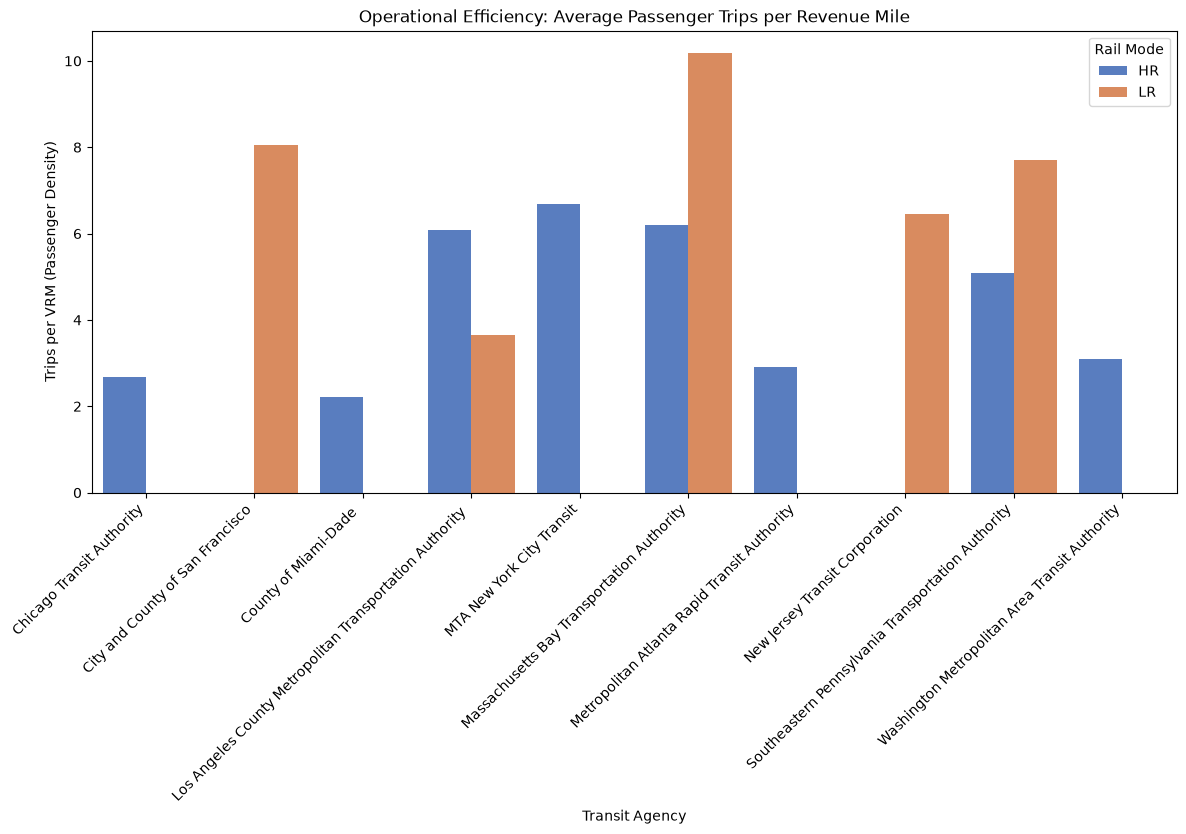

In [36]:
summary_chart = rail_df.groupby(['Agency', 'Mode']).agg(
    Total_UPT=('UPT_num', 'sum'),
    Total_VRM=('VRM_num', 'sum')
).reset_index()

summary_chart['Trips_per_VRM'] = summary_chart['Total_UPT'] / summary_chart['Total_VRM']

plt.figure(figsize=(14, 6))
sns.barplot(
    data=summary_chart, 
    x='Agency', 
    y='Trips_per_VRM', 
    hue='Mode', 
    palette='muted'
)
plt.title('Operational Efficiency: Average Passenger Trips per Revenue Mile')
plt.xlabel('Transit Agency')
plt.ylabel('Trips per VRM (Passenger Density)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Rail Mode')
plt.show()

In [37]:
# Extra Credit - a defensible train/test-evaluated model

# How effectively service supply can predict passenger demand

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = rail_df[['VRM_num']]
y = rail_df['UPT_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"R-squared Score: {r2_score(y_test, y_pred):.4f}")
print(f"Coefficient (Slope): {model.coef_[0]:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

R-squared Score: 0.9140
Coefficient (Slope): 6.6042
Intercept: -4063780.9596


Regression Model Results & Interpretation

R^2 Score of (0.9140) indicates a strong linear fit. 91.4% of passenger ridership is explained by vehicle revenue miles, proving that service supply is a primary driver of ridership demand.

Slope (6.60) suggests that for every single mile a train runs, the system get an average of about 6.6 passenger boardings added.

Intercept of (-4,063,781) shows the model's mathematical baseline. The negative intercept is a mathematical artifact of linear extrapolation. Because the dataset focuses on the top 10 largest transit agencies, the model lacks baseline data near zero. In reality, passenger demand floors out at zero rather than dropping into negative values, demonstrating why linear models should not be interpreted literally at extreme baseline values.

Ethics, Bias, and Limitations

Pandemic Distortion
National transit data includes the massive drop in ridership during 2020–2021 and subsequent recovery patterns, which can heavily skew linear regression trends and long-term forecasts.

Data Reporting Inconsistencies
Different agencies may define Ridership or Vehicle Revenue Miles differently based on counting technologies like fares, gate entry, and APC (automated passenger counters).

Equity & Service Supply 
Vehicle Revenue Miles does not always equal equitable access. Transit agencies for the rail has historically been used in richer neighborhoods in contrast to the bus lines that cities run. So there can be a limitation in the report as this one only covers the rail system and not the bus fleet of each agency. 

AI Prompt 

1) All my charts are difficult to see and are jumbled together, what is a good way to display the data for easy reading?
   Implemented size recommendations so the chart is readable and included a legend for more clarity.

2) How can I seperate the lines for heavy rail and light rail to show that on the same chart without spreading it?
   Implemented line with 'hue' that was able to place the light rail lines into the chart.